# Exercice 3 : Vérifier un IoC dans le renseignement sur les menaces

> **En une phrase :** des milliers de défenseurs publient chaque jour les IP, domaines et empreintes qu'ils ont vus attaquer. On vérifie nos attaquants dans ces listes… et on découvre qu'un IoC a une **date de péremption**.

**Le scénario.** Étape « Vérification IOC » du cours : *est-ce que l'IP, le domaine, le hash est connu ?* Vous avez les IP de l'exercice 1 et deux fichiers suspects. Vous interrogez le renseignement public.

**Les sources (gratuites, sans inscription).**
- *IPsum* : agrège chaque jour **une trentaine de listes noires** publiques et dit, pour chaque IP, dans combien de listes elle apparaît.
- *blocklist.de* : IP qui ont attaqué des serveurs SSH de volontaires dans les **dernières 48 heures**.
- *CIRCL hashlookup* (CERT du Luxembourg) : base d'empreintes de fichiers **connus** (logiciels légitimes et quelques maliciels).

**Le plan.**
1. Télécharger le renseignement du jour.
2. Nos attaquants y sont-ils ?
3. Les IoC frais : qui attaque **aujourd'hui** ?
4. Vérifier une empreinte de fichier.

## Étape 0 : exécutez cette cellule en premier
Le notebook est **autonome** : il fonctionne tel quel sur Colab (ouvert depuis Drive) ou en local. Elle doit afficher **Prêt**.

In [1]:
import re, requests
import pandas as pd

URL_SSH = "https://raw.githubusercontent.com/logpai/loghub/master/OpenSSH/OpenSSH_2k.log"

def charger_ssh():
    """Télécharge le journal SSH et le range dans un tableau : une ligne = un événement."""
    lignes = requests.get(URL_SSH, timeout=30).text.splitlines()
    motif = re.compile(r"^(\w{3}\s+\d+ \d\d:\d\d:\d\d) \S+ sshd\[\d+\]: (.*)$")
    evenements = []
    for ligne in lignes:
        m = motif.match(ligne)
        if m:
            ip = re.search(r"\d+\.\d+\.\d+\.\d+", m.group(2))
            evenements.append({"heure": pd.to_datetime("2016 " + m.group(1), format="%Y %b %d %H:%M:%S"),  # l'année n'est pas écrite dans le journal
                               "message": m.group(2),
                               "ip": ip.group() if ip else None})
    return pd.DataFrame(evenements), lignes

evenements, _ = charger_ssh()
echecs = evenements[evenements["message"].str.startswith("Failed password")]
nos_attaquants = echecs["ip"].value_counts()           # les 23 IP de l'exercice 1
print('Prêt')

Prêt


## Étape 1 : Télécharger le renseignement du jour
**Ce qu'on fait :** on récupère IPsum (une ligne = une IP + le nombre de listes noires où elle figure).

# Last update: Tue, 10 Nov 2026 03:00:45 +0100


130 398 IP signalées


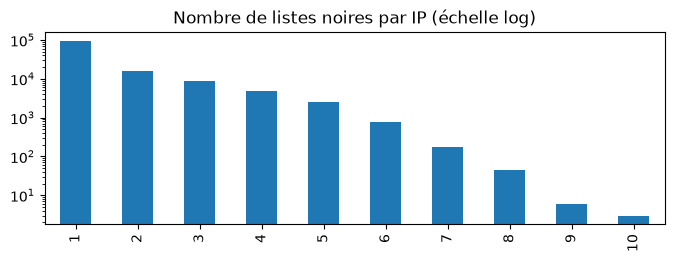

In [2]:
texte = requests.get("https://raw.githubusercontent.com/stamparm/ipsum/master/ipsum.txt", timeout=30).text
print(texte.splitlines()[3])                           # la date de mise à jour
ipsum = {ligne.split()[0]: int(ligne.split()[1]) for ligne in texte.splitlines() if not ligne.startswith("#")}

print(f"{len(ipsum):,} IP signalées".replace(",", " "))
pd.Series(ipsum).value_counts().sort_index().plot(kind="bar", logy=True, figsize=(8, 2.5),
                                                  title="Nombre de listes noires par IP (échelle log)");

**👀 Ce qu'on doit voir :** une mise à jour **d'aujourd'hui**, et **≈ 130 000 IP**. La plupart ne sont que dans **1** liste (peu fiable) ; quelques centaines sont dans 5 listes ou plus (presque certainement malveillantes).

## Étape 2 : Nos attaquants y sont-ils ?
**Ce qu'on fait :** on cherche chacune des 23 IP de l'exercice 1.

In [3]:
verif = pd.DataFrame({"échecs dans notre journal": nos_attaquants,
                      "listes noires aujourd'hui": [ipsum.get(ip, 0) for ip in nos_attaquants.index]})
print("IP connues du renseignement :", (verif["listes noires aujourd'hui"] > 0).sum(), "sur", len(verif))
verif.head(8)

IP connues du renseignement : 0 sur 23


,échecs dans notre journal,listes noires aujourd'hui
ip,,
183.62.140.253,286,0
187.141.143.180,80,0
103.99.0.122,46,0
112.95.230.3,26,0
5.188.10.180,18,0
185.190.58.151,17,0
123.235.32.19,7,0
119.4.203.64,6,0


**👀 Ce qu'on doit voir :** **0 sur 23** (ou presque). Même 183.62.140.253, qui a fait 286 essais en 10 minutes, est **inconnue** aujourd'hui.

**❓ Question pour la classe :** ces IP ont attaqué sans se cacher. Pourquoi ne sont-elles dans aucune liste ?

*Réponse : parce que le journal date de **plusieurs années**. Les listes noires **retirent** les IP qui n'attaquent plus : une IP est souvent une machine piratée (nettoyée depuis), un serveur loué quelques jours, ou une adresse réattribuée à un client innocent. Bloquer des IP trop vieilles, c'est bloquer des innocents. **Un IoC réseau se périme en jours ou en semaines.***

## Étape 3 : Les IoC frais : qui attaque aujourd'hui ?
**Ce qu'on fait :** on télécharge les attaquants SSH des **48 dernières heures** (blocklist.de) et on regarde s'ils sont aussi dans IPsum.

In [4]:
recents = requests.get("https://lists.blocklist.de/lists/ssh.txt", timeout=30).text.split()
dans_ipsum = [ip for ip in recents if ip in ipsum]
print(f"{len(recents)} IP ont attaqué en SSH dans les 48 dernières heures")
print(f"{len(dans_ipsum)} d'entre elles sont aussi dans IPsum ({len(dans_ipsum) / len(recents):.0%})")

# D'où viennent-elles ? (géolocalisation de 100 d'entre elles, service gratuit ip-api.com)
geo = requests.post("http://ip-api.com/batch?fields=country,isp,hosting", json=recents[:100], timeout=30).json()
geo = pd.DataFrame(geo)
print("\nHébergeurs / centres de données :", geo["hosting"].sum(), "sur 100")
geo["country"].value_counts().head(6)

4429 IP ont attaqué en SSH dans les 48 dernières heures
4011 d'entre elles sont aussi dans IPsum (91%)

Hébergeurs / centres de données : 26 sur 100


country
China           52
Singapore       10
South Korea      7
Hong Kong        7
Slovenia         6
South Africa     4
Name: count, dtype: int64

**👀 Ce qu'on doit voir :** **≈ 4 400 IP** en 48 heures, dont **≈ 90 %** déjà dans IPsum (les listes se recoupent). Les pays varient chaque jour (souvent la Chine en tête). Environ **un quart** sont des **hébergeurs** (serveurs loués) ; les autres sont des connexions d'abonnés, souvent des ordinateurs ou objets connectés **piratés** qui attaquent à l'insu de leur propriétaire.

## Étape 4 : Vérifier une empreinte de fichier
**Ce qu'on fait :** comme au Ch. 5 (ex. 1), un fichier est identifié par son **empreinte**. On en vérifie trois auprès de CIRCL : on n'envoie que l'empreinte, jamais le fichier.
- le fichier de test **EICAR** (un faux virus inoffensif que tous les antivirus détectent, fait pour les tests) ;
- un fichier système de **Windows** ;
- un fichier que **vous** venez de créer.

In [5]:
import hashlib

def hashlookup(md5):
    r = requests.get(f"https://hashlookup.circl.lu/lookup/md5/{md5}", timeout=15)
    if r.status_code == 404:
        return "INCONNU de la base"
    info = r.json()
    if "KnownMalicious" in info:
        return f"MALVEILLANT connu (signalé par {info['KnownMalicious']}) : {info.get('FileName')}"
    return f"Connu et légitime : {info.get('FileName', '?')[:60]}"

mon_fichier = "Rapport_8INF857_" + str(pd.Timestamp.now())            # <-- MODIFIABLE
fichiers = {
    "EICAR (test antivirus)": "44D88612FEA8A8F36DE82E1278ABB02F",
    "Fichier système Windows": "8ED4B4ED952526D89899E723F3488DE4",
    "Mon fichier tout neuf":   hashlib.md5(mon_fichier.encode()).hexdigest(),
}
for nom, empreinte in fichiers.items():
    print(f"{nom:25} {empreinte[:12]}… → {hashlookup(empreinte)}")

EICAR (test antivirus)    44D88612FEA8… → MALVEILLANT connu (signalé par malshare.com) : eicar.com


Fichier système Windows   8ED4B4ED9525… → Connu et légitime : wow64_microsoft-windows-i..timezones.resources_31bf3856ad364


Mon fichier tout neuf     70e9df9cdff5… → INCONNU de la base


**👀 Ce qu'on doit voir :** EICAR → **malveillant connu**. Le fichier Windows → **connu et légitime** (il fait partie de la base NSRL du NIST). Votre fichier → **inconnu**.

**❓ Question pour la classe :** « inconnu de la base » : le fichier est-il sain ?

*Réponse : **non**, on ne sait rien. Un maliciel recompilé, ou simplement modifié d'un octet, a une empreinte **toute neuve** : il est « inconnu » partout. C'est pourquoi la détection par empreinte (antivirus classique) échoue face aux maliciels qui se modifient à chaque copie, et pourquoi l'IA, qui génère des variantes à volonté, affaiblit encore les signatures. Les listes de fichiers **légitimes** restent très utiles dans l'autre sens : écarter en un instant 99 % des fichiers d'une machine pour ne regarder que le reste.*

## Ce qu'il faut retenir : la pyramide de la douleur
Plus un IoC est **facile à changer** pour l'attaquant, moins il dure (David Bianco, 2013) :

| IoC | Pour l'attaquant, le changer coûte… | Durée de vie |
|---|---|---|
| Empreinte de fichier | recompiler : **trivial** | minutes |
| Adresse IP | louer un autre serveur : **facile** | jours |
| Nom de domaine | en acheter un autre : **un peu ennuyeux** | semaines |
| Outils | en écrire d'autres : **difficile** | mois |
| Comportement (TTP) | changer sa façon d'opérer : **très difficile** | années |

- Le renseignement sur les menaces est **gratuit** et énorme, mais il **se périme** : on vérifie toujours la **date** et le **nombre de sources**.
- « Inconnu » ne veut pas dire « sain ».
- Le haut de la pyramide (le **comportement**) dure le plus longtemps : c'est ce qu'on détecte à l'exercice suivant.

**Exercice suivant :** détecter sans IoC, en cherchant ce qui sort de l'ordinaire.